# EDA (Exploratory Data Analysis) of the Abalone dataset

**Goal**: predict the age of an abalone, measured as its number of `Rings` (age ≈ Rings + 1.5 years), from physical measurements that are easy to obtain. The traditional method requires cutting the shell, staining it and counting rings under a microscope, which is slow.

This notebook answers the following questions:
1. What does the data look like (types, missing values, duplicates, outliers)?
2. How is the target `Rings` distributed?
3. Which features relate to `Rings`, and how (linearly or not)?
4. What does this imply for the modelling step?

# Imports

In [17]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from skrub import TableReport

pd.set_option("display.max_columns", 500)
sns.set_theme(style="whitegrid", palette="deep")

# Data

In [18]:
df = pd.read_csv("../data/abalone.csv")
print(f"Shape: {df.shape}")
df.head(5)

Shape: (4177, 9)


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


| Column | Type | Description |
|---|---|---|
| `Sex` | categorical | M (male), F (female), I (infant) |
| `Length` | continuous | longest shell measurement |
| `Diameter` | continuous | perpendicular to length |
| `Height` | continuous | with meat in shell |
| `Whole weight` | continuous | whole abalone |
| `Shucked weight` | continuous | weight of the meat |
| `Viscera weight` | continuous | gut weight (after bleeding) |
| `Shell weight` | continuous | after being dried |
| `Rings` | integer | **target**, +1.5 gives the age in years |

The continuous measurements have been scaled (lengths divided by 200 in the original data), so the absolute values are not directly interpretable.

# Data quality

In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   str    
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 293.8 KB


In [20]:
print("Missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())

Missing values: 0
Duplicated rows: 0


In [21]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Length,4177.0,0.523992,0.120093,0.0750,0.4500,0.5450,0.615,0.8150
Diameter,4177.0,0.407881,0.099240,0.0550,0.3500,0.4250,0.480,0.6500
Height,4177.0,0.139516,0.041827,0.0000,0.1150,0.1400,0.165,1.1300
Whole weight,4177.0,0.828742,0.490389,0.0020,0.4415,0.7995,1.153,2.8255
Shucked weight,4177.0,0.359367,0.221963,0.0010,0.1860,0.3360,0.502,1.4880
Viscera weight,4177.0,0.180594,0.109614,0.0005,0.0935,0.1710,0.253,0.7600
Shell weight,4177.0,0.238831,0.139203,0.0015,0.1300,0.2340,0.329,1.0050
Rings,4177.0,9.933684,3.224169,1.0000,8.0000,9.0000,11.000,29.0000


In [22]:
TableReport(df)

Processing column   9 / 9


,,,,,,,,,


In [23]:
# Zero-sized abalones are physically impossible
df[(df[["Length", "Diameter", "Height"]] == 0).any(axis=1)]

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
1257,I,0.430,0.34,0.0,0.428,0.2065,0.0860,0.1150,8
3996,I,0.315,0.23,0.0,0.134,0.0575,0.0285,0.3505,6


**Conclusions**
- No missing values and no duplicated rows.
- `Height` equals 0 for 2 rows, which is impossible: these are data errors and should be removed before modelling.
- `Height` has an extreme maximum (1.13, versus a 99.9th percentile of ~0.25), which is probably a typo. We look at the outliers below.

# Target: `Rings`

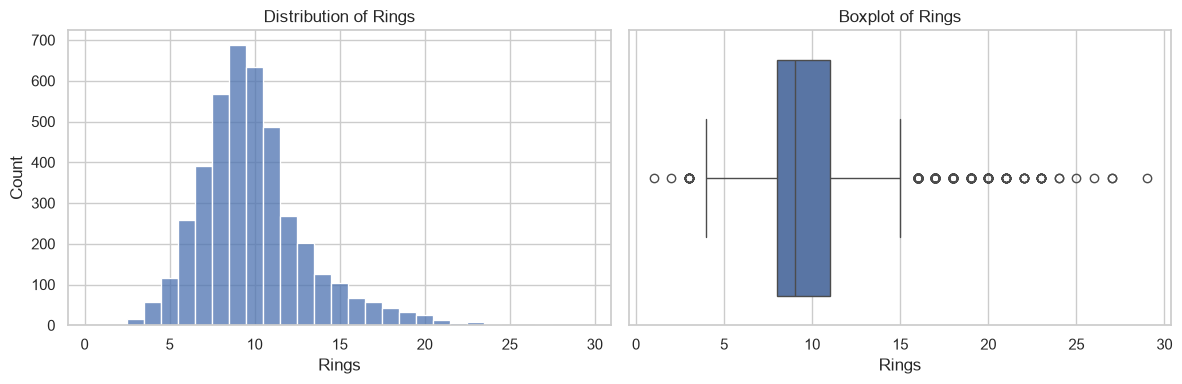

Skewness: 1.11


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Rings"], discrete=True, ax=axes[0])
axes[0].set_title("Distribution of Rings")
sns.boxplot(x=df["Rings"], ax=axes[1])
axes[1].set_title("Boxplot of Rings")
plt.tight_layout()
plt.show()
print(f"Skewness: {df['Rings'].skew():.2f}")

**Conclusions**
- `Rings` ranges from 1 to 29 with a mean of ~9.9; most values are between 8 and 11.
- The distribution is right-skewed (skewness ≈ 1.1) with a few very old abalones. Errors will likely be larger on the high values, so we should look at MAE and not only RMSE.
- The target is a count, but it can be treated as a regression problem.

# Categorical feature: `Sex`

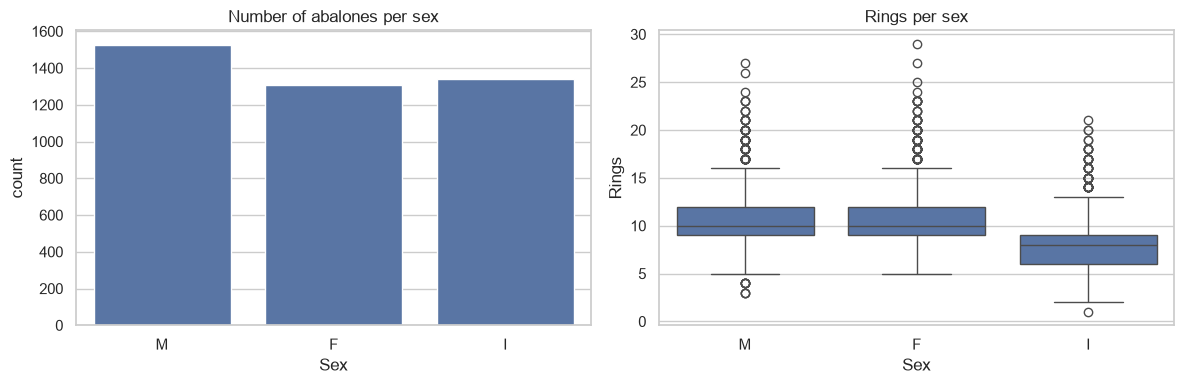

,count,mean,std
Sex,,,
F,1307,11.129304,3.104256
I,1342,7.890462,2.511554
M,1528,10.705497,3.026349


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Sex", order=["M", "F", "I"], ax=axes[0])
axes[0].set_title("Number of abalones per sex")
sns.boxplot(data=df, x="Sex", y="Rings", order=["M", "F", "I"], ax=axes[1])
axes[1].set_title("Rings per sex")
plt.tight_layout()
plt.show()
df.groupby("Sex")["Rings"].agg(["count", "mean", "std"])

**Conclusions**
- The three classes are well balanced.
- Infants (`I`) have clearly fewer rings (~7.9) than males and females (~10.7 and ~11.1), which is expected since they are younger.
- Males and females are almost indistinguishable in terms of `Rings`: the main information carried by `Sex` is "infant or adult". It must be one-hot encoded for linear models.

# Numerical features

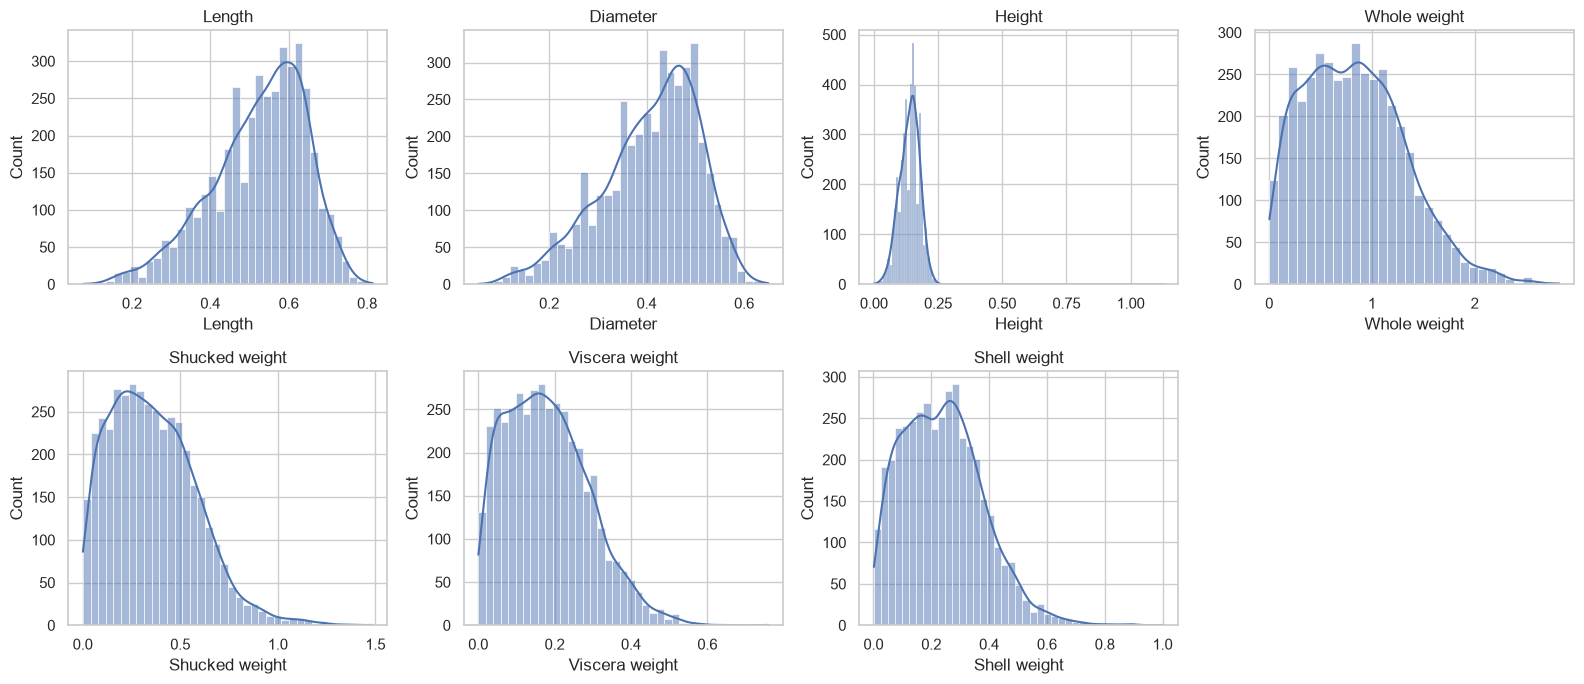

In [26]:
num_cols = df.select_dtypes("number").columns.drop("Rings")

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols, strict=False):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

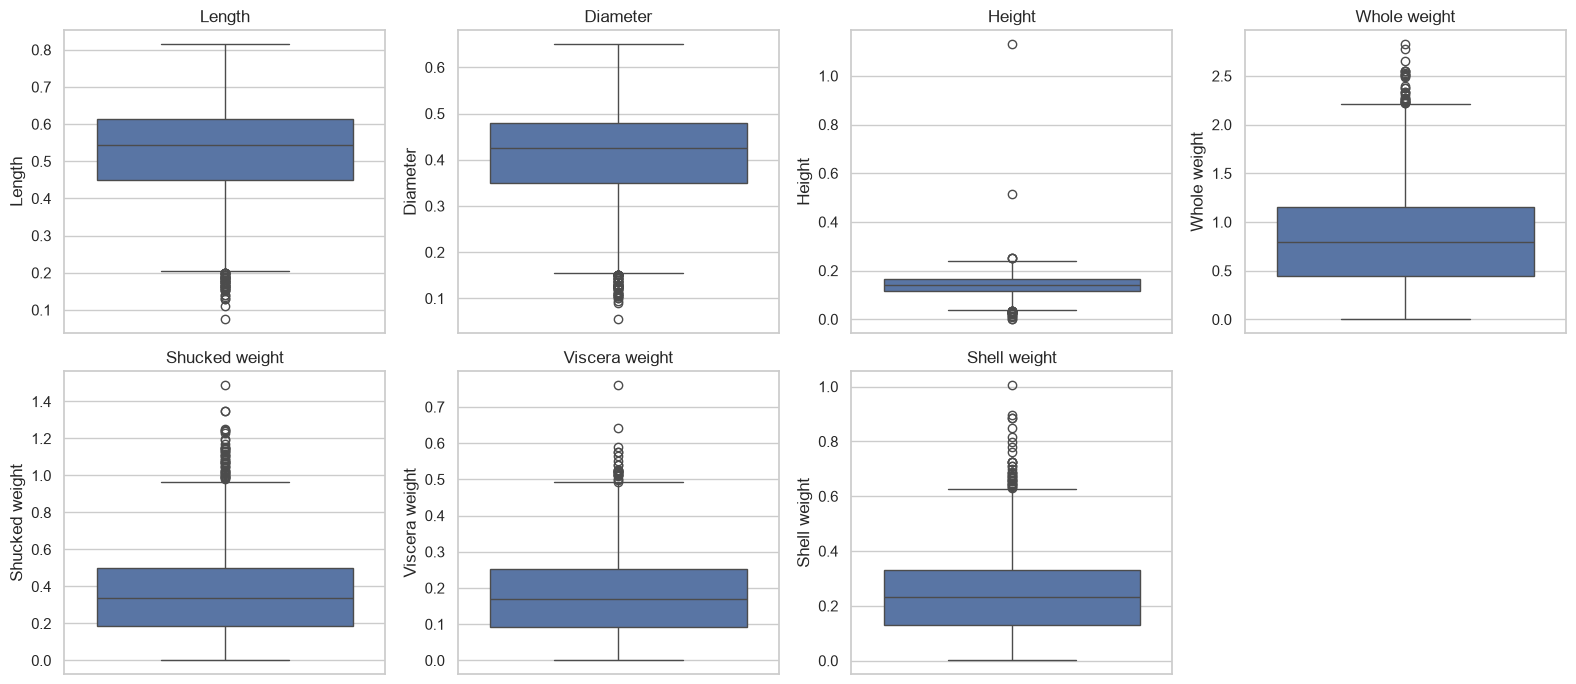

In [27]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols, strict=False):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [28]:
# Rows with the most extreme Height values
df.nlargest(3, "Height")

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
2051,F,0.455,0.355,1.130,0.594,0.3320,0.1160,0.1335,8
1417,M,0.705,0.565,0.515,2.210,1.1075,0.4865,0.5120,10
1428,F,0.815,0.650,0.250,2.255,0.8905,0.4200,0.7975,14


**Conclusions**
- `Length` and `Diameter` are left-skewed (few very small abalones), while the weights are right-skewed.
- Outliers appear on every feature, mostly on the weights and on `Height`.
- Two rows have a `Height` above 0.5. The first one (1.13 for a length of 0.455) is clearly a typo; the second (0.515 for a length of 0.705) is also far from the rest of the distribution. Both should be dropped.

# Relationship with the target

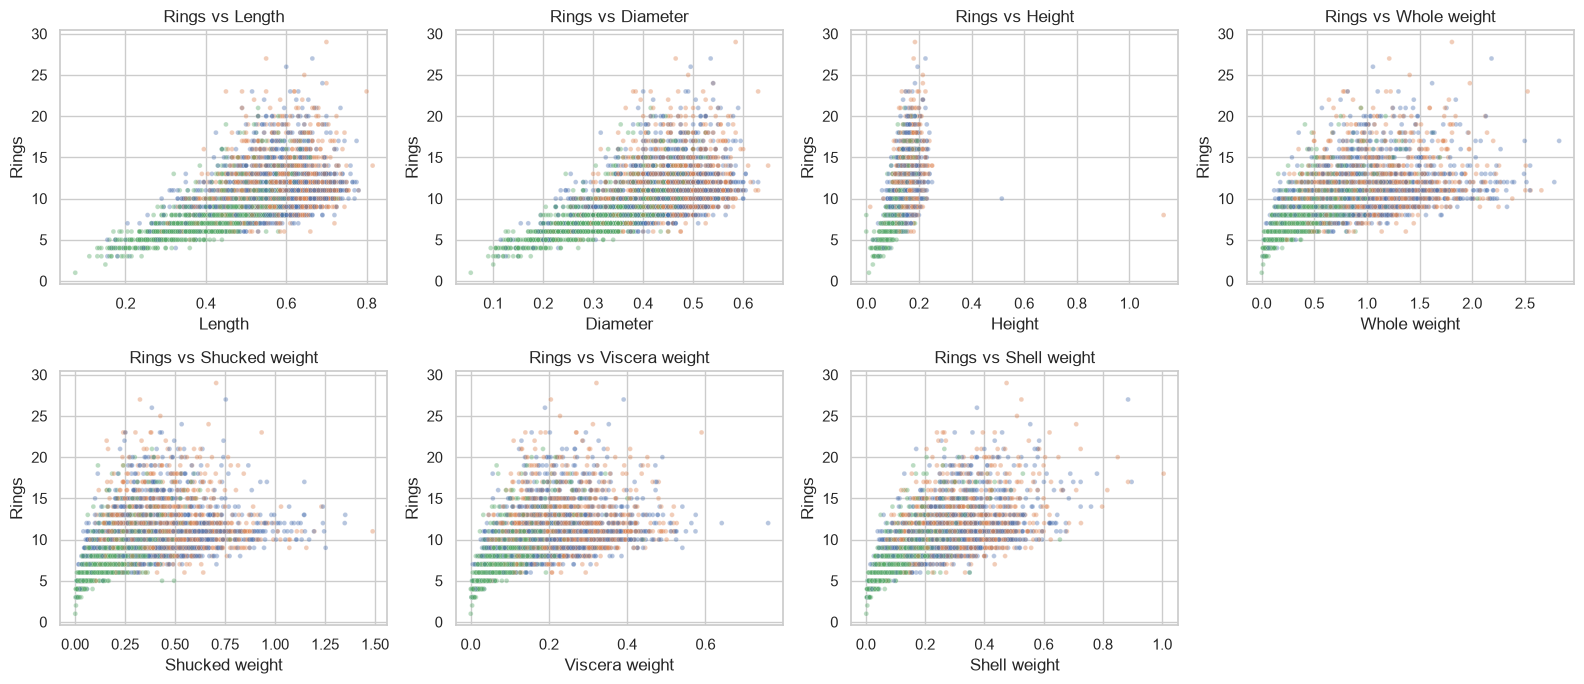

In [29]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols, strict=False):
    sns.scatterplot(
        data=df, x=col, y="Rings", hue="Sex", alpha=0.4, s=12, ax=ax, legend=False
    )
    ax.set_title(f"Rings vs {col}")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

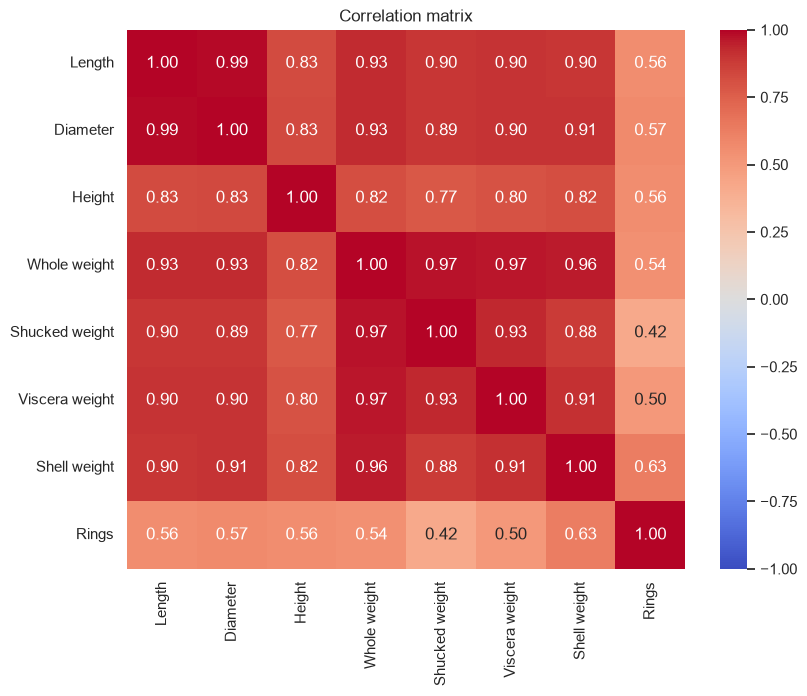

Shell weight      0.627574
Diameter          0.574660
Height            0.557467
Length            0.556720
Whole weight      0.540390
Viscera weight    0.503819
Shucked weight    0.420884
Name: Rings, dtype: float64

In [30]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()
corr["Rings"].drop("Rings").sort_values(ascending=False)

**Conclusions**
- Every feature is positively correlated with `Rings`; `Shell weight` (0.63) is the strongest, followed by `Diameter`, `Height` and `Length` (~0.56-0.57).
- The relationship is **not linear**: abalones stop growing in size as they age, so `Rings` varies a lot for a given size, especially for large abalones (the scatter fans out). The relation looks closer to a concave curve, and the variance increases with the size.
- The features are **strongly collinear** (`Length` and `Diameter` ≈ 0.99, the four weights between 0.88 and 0.97). A plain linear regression will work but its coefficients will be unstable; regularisation (Ridge) or tree-based models can help.
- The best single feature only explains ~40% of the variance of `Rings` (0.63²), so we should not expect a very high R² from physical measurements alone.

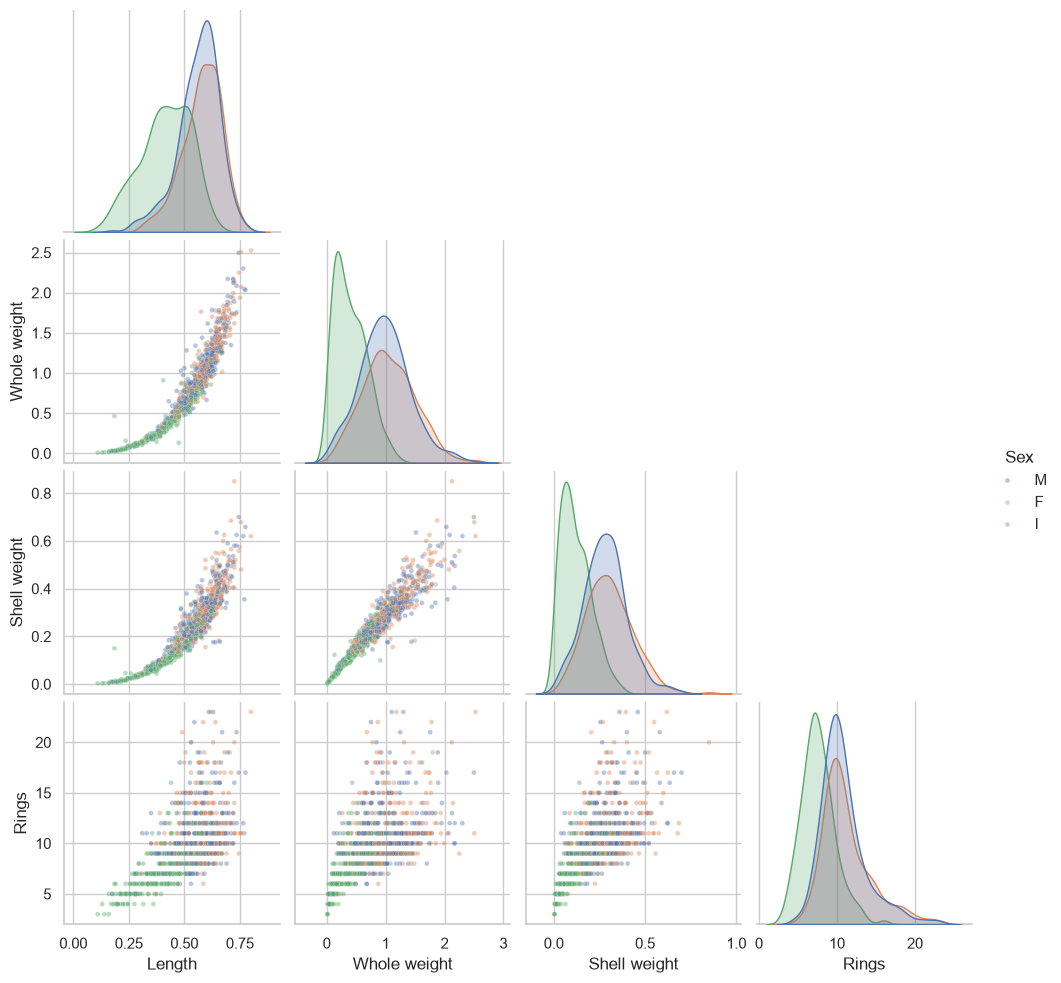

In [31]:
sns.pairplot(
    df.sample(1000, random_state=42),
    vars=["Length", "Whole weight", "Shell weight", "Rings"],
    hue="Sex",
    plot_kws={"alpha": 0.4, "s": 12},
    corner=True,
)
plt.show()

# Summary and implications for modelling

1. **Cleaning**: remove the rows with `Height` = 0 and the 2 extreme `Height` outliers (> 0.5).
2. **Encoding**: one-hot encode `Sex`.
3. **Target**: right-skewed; evaluate with MAE and RMSE, and consider testing a `log(Rings)` transformation.
4. **Features**: strongly collinear and with a non-linear link to the target. Start with a simple linear model as a baseline, then try Ridge or tree-based models (e.g. RandomForest, GradientBoosting).
5. **Expectations**: the signal is limited (best single correlation ≈ 0.63), so the errors will remain noticeable, especially for old abalones.